Center: [[-2.01756639  0.81503828]
 [ 0.92899618  0.98092128]
 [-0.92246998 -0.99968836]
 [ 0.67147549 -1.08148678]
 [ 2.07278677  2.15762469]
 [-0.62528321  1.35310067]
 [-1.95338311  2.76167749]
 [-0.37250435  0.040852  ]
 [-1.49135368 -2.52464566]
 [ 1.91668624 -1.04111859]]
Standard Deviation: 0.5914177167711093
Model Accuracy: 85.5


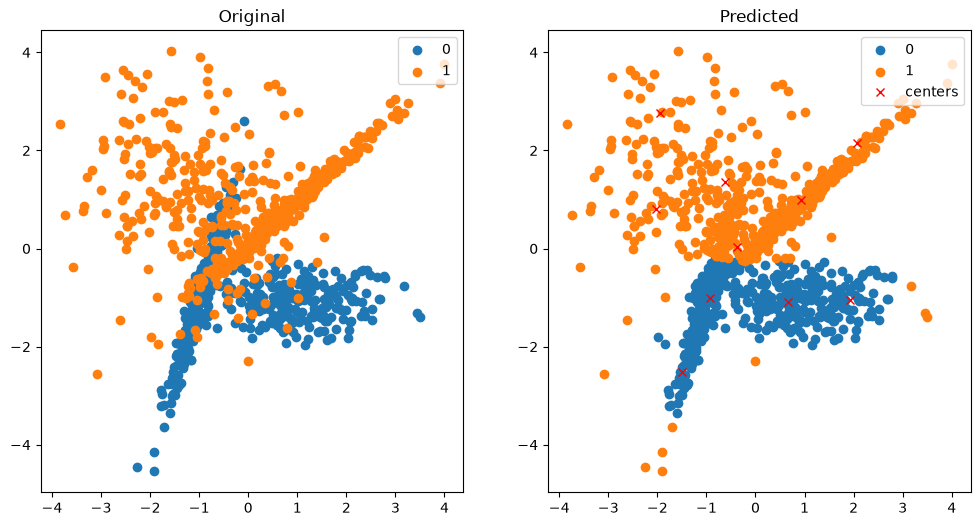

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from scipy.spatial.distance import cdist

X,y = make_classification(n_samples=1000,n_features=2,n_classes=2,
n_clusters_per_class=2,n_redundant=0,random_state=42)

X1,X2,y1,y2 = train_test_split(X,y,test_size=0.2)

k = KMeans(n_clusters=10,random_state=42,n_init=10)
k.fit(X1)
centers = k.cluster_centers_

std = np.mean(cdist(centers,centers))/np.sqrt(20)

def rbf(X):
    return np.exp(-cdist(X,centers,'sqeuclidean')/(2*std**2))

a = np.hstack([rbf(X1),np.ones((len(X1),1))])
b = np.hstack([rbf(X2),np.ones((len(X2),1))])

model = LogisticRegression()
model.fit(a,y1)

pred = model.predict(b)
print("Center:",centers)
print("Standard Deviation:",std)
print("Model Accuracy:",accuracy_score(y2,pred)*100)

def plot(X,y):
    plt.scatter(X[y==0,0],X[y==0,1],label="0")
    plt.scatter(X[y==1,0],X[y==1,1],label="1")
    plt.legend(loc="upper right")

plt.figure(figsize=(12,6))

plt.subplot(121)
plt.title("Original")
plot(X,y)

plt.subplot(122)
plt.title("Predicted")
plot(X,model.predict(np.hstack([rbf(X),np.ones((len(X),1))])))
plt.plot(centers[:,0],centers[:,1],'rx',label="centers")
plt.legend(loc="upper right")

plt.show()